# Conformal Prediction: ejemplo práctico

**Objetivo.** Tomar un modelo de regresión cualquiera y convertir sus predicciones puntuales en **intervalos con cobertura garantizada**, y luego comprobar con datos que la garantía se cumple.

**Qué hace este notebook**

1. Entrena un Random Forest para predecir el valor de viviendas.
2. Muestra por qué un intervalo "ingenuo" falla.
3. Implementa **split conformal prediction a mano** (son unas pocas líneas).
4. Verifica la cobertura empírica contra la cobertura pedida.
5. Muestra una limitación (ancho constante) y cómo la resuelve una variante, **CQR**.

Todo es reproducible: semilla fija, dataset incluido en el repositorio y versiones fijadas en `requirements.txt`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.model_selection import train_test_split

SEED = 42       # semilla fija para reproducibilidad
ALPHA = 0.10    # error tolerado -> cobertura objetivo = 1 - ALPHA = 90%

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

# Estilo de las gráficas
AZUL, AZUL_CLARO, NARANJA = "#2a78d6", "#9ec5f4", "#eb6834"
TEXTO, TEXTO_2, REJILLA, FONDO = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 11, "text.color": TEXTO,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": TEXTO_2, "axes.edgecolor": REJILLA,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": REJILLA, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False,
})

## 1. Problema y datos

Usamos **California Housing** (censo de 1990): cada fila es un distrito censal de California y la variable objetivo es el **valor mediano de las viviendas** del distrito. Trabajamos el objetivo en miles de USD.

Un detalle del dataset: el valor está **topado en 500 mil USD** (cerca del 5% de los distritos aparece con ese tope), así que los distritos más caros son más difíciles de predecir.

Es el mismo tipo de pregunta del inicio de la exposición: *el modelo dice que la vivienda vale X, pero ¿en qué rango esperamos que esté el valor real?*

In [2]:
df = pd.read_csv("data/housing.csv").dropna()   # 207 filas sin `total_bedrooms` se descartan

X = pd.get_dummies(df.drop(columns="median_house_value"), columns=["ocean_proximity"]).astype(float)
y = df["median_house_value"] / 1000              # miles de USD

print(f"{len(df)} distritos, {X.shape[1]} variables predictoras")
df.head()

20433 distritos, 13 variables predictoras


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## 2. División de los datos

Conformal prediction necesita **tres** conjuntos, no dos:

| Conjunto | Para qué | Proporción |
|---|---|---|
| Entrenamiento | Ajustar el modelo | 60% |
| **Calibración** | Medir qué tan grandes son los errores del modelo en datos que no vio | 20% |
| Prueba | Comprobar que la cobertura se cumple | 20% |

In [3]:
X_train, X_resto, y_train, y_resto = train_test_split(X, y, test_size=0.40, random_state=SEED)
X_cal, X_test, y_cal, y_test = train_test_split(X_resto, y_resto, test_size=0.50, random_state=SEED)

print(f"Entrenamiento: {len(X_train)} | Calibración: {len(X_cal)} | Prueba: {len(X_test)}")

Entrenamiento: 12259 | Calibración: 4087 | Prueba: 4087


## 3. El modelo

Un Random Forest sin ajuste fino. Conformal prediction lo trata como **caja negra**: lo único que necesita es su método `predict`.

In [4]:
modelo = RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1)
modelo.fit(X_train, y_train)

pred_cal = modelo.predict(X_cal)
pred_test = modelo.predict(X_test)

mae = np.mean(np.abs(y_test - pred_test))
print(f"Error absoluto medio en prueba: {mae:.1f} mil USD")

Error absoluto medio en prueba: 31.8 mil USD


## 4. El intento ingenuo (y por qué falla)

Una idea natural: mirar los errores del modelo en los datos de **entrenamiento** y usar su percentil 90 como margen.

El problema es que el modelo ya vio esos datos, así que sus errores ahí son mucho más pequeños que los que cometerá con datos nuevos.

In [5]:
errores_train = np.abs(y_train - modelo.predict(X_train))
margen_ingenuo = np.quantile(errores_train, 1 - ALPHA)

cobertura_ingenua = np.mean(np.abs(y_test - pred_test) <= margen_ingenuo)

print(f"Margen ingenuo:      ±{margen_ingenuo:.1f} mil USD")
print(f"Cobertura pedida:    {1 - ALPHA:.0%}")
print(f"Cobertura obtenida:  {cobertura_ingenua:.1%}")

Margen ingenuo:      ±28.0 mil USD
Cobertura pedida:    90%
Cobertura obtenida:  62.3%


El intervalo promete 90% y queda muy por debajo. Por eso existe el conjunto de calibración.

## 5. Split conformal prediction, a mano

Tres pasos:

1. **Puntaje de no conformidad** en cada dato de calibración: $s_i = |y_i - \hat{y}_i|$
2. **Umbral** $\hat{q}$: el puntaje que ocupa la posición $\lceil (n+1)(1-\alpha) \rceil$ al ordenarlos de menor a mayor
3. **Intervalo** para un dato nuevo: $[\hat{y} - \hat{q},\ \hat{y} + \hat{q}]$

In [6]:
def cuantil_conformal(puntajes, alpha):
    # Umbral q̂: el puntaje en la posición ceil((n+1)(1-alpha)) de menor a mayor.
    puntajes = np.sort(np.asarray(puntajes))
    n = len(puntajes)
    k = int(np.ceil((n + 1) * (1 - alpha)))
    if k > n:                      # muy pocos datos de calibración para ese alpha
        return np.inf
    return puntajes[k - 1]


# Paso 1: puntajes de no conformidad en calibración
puntajes = np.abs(y_cal - pred_cal).to_numpy()

# Paso 2: umbral
q_hat = cuantil_conformal(puntajes, ALPHA)

# Paso 3: intervalos para los datos de prueba
inferior = pred_test - q_hat
superior = pred_test + q_hat

n = len(puntajes)
print(f"n de calibración = {n}  ->  posición {int(np.ceil((n + 1) * (1 - ALPHA)))} de {n}")
print(f"q̂ = {q_hat:.1f} mil USD  ->  intervalo = predicción ± {q_hat:.1f}")

n de calibración = 4087  ->  posición 3680 de 4087
q̂ = 75.1 mil USD  ->  intervalo = predicción ± 75.1


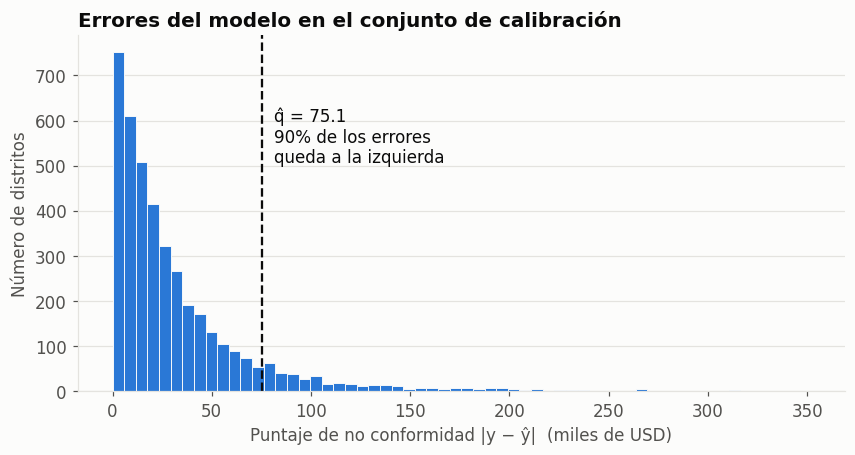

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.hist(puntajes, bins=60, color=AZUL, edgecolor=FONDO, linewidth=0.6)
ax.axvline(q_hat, color=TEXTO, linewidth=1.5, linestyle="--")
ax.annotate(f"q̂ = {q_hat:.1f}\n{1 - ALPHA:.0%} de los errores\nqueda a la izquierda",
            xy=(q_hat, ax.get_ylim()[1] * 0.80), xytext=(8, 0), textcoords="offset points",
            va="top", color=TEXTO)
ax.set_title("Errores del modelo en el conjunto de calibración")
ax.set_xlabel("Puntaje de no conformidad |y − ŷ|  (miles de USD)")
ax.set_ylabel("Número de distritos")
fig.savefig(FIG_DIR / "01_puntajes_calibracion.png")
plt.show()

## 6. Resultado: predicciones con intervalo

Ya no decimos solo "el valor es X": damos un rango en el que esperamos el valor real 9 de cada 10 veces.

In [8]:
resultado = pd.DataFrame({
    "valor_real": y_test.to_numpy(),
    "prediccion": pred_test,
    "inferior": inferior,
    "superior": superior,
})
resultado["cubierto"] = resultado["valor_real"].between(resultado["inferior"], resultado["superior"])
resultado.head(8).round(1)

,valor_real,prediccion,inferior,superior,cubierto
0,168.3,197.5,122.4,272.6,True
1,143.3,171.9,96.8,247.0,True
2,140.7,108.0,32.9,183.1,True
3,84.4,86.4,11.3,161.5,True
4,281.1,238.6,163.5,313.7,True
5,138.1,147.3,72.2,222.4,True
6,297.6,297.9,222.8,373.1,True
7,87.5,104.7,29.6,179.8,True


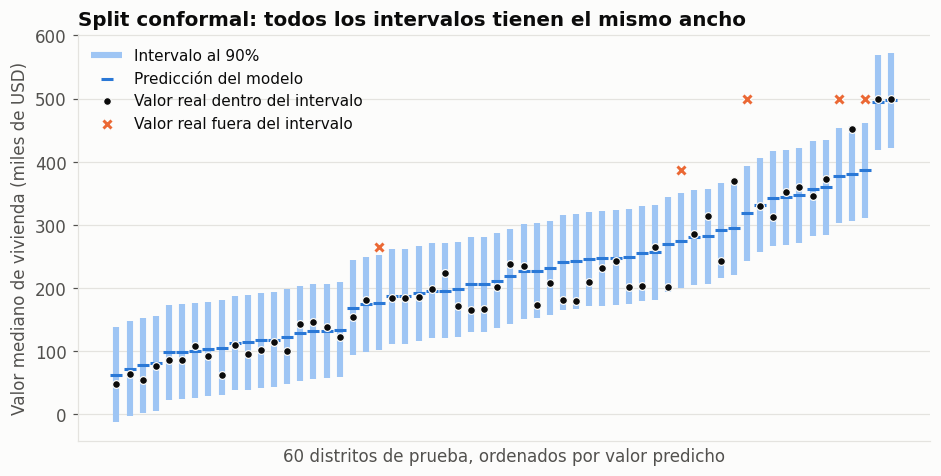

En esta muestra: 55 de 60 valores reales dentro del intervalo


In [9]:
def grafica_intervalos(res, titulo, archivo, etiqueta_pred="Predicción del modelo", n_muestra=60):
    # Muestra aleatoria de distritos de prueba, ordenados por predicción.
    m = res.sample(n_muestra, random_state=SEED).sort_values("prediccion").reset_index(drop=True)
    dentro, fuera = m[m["cubierto"]], m[~m["cubierto"]]

    fig, ax = plt.subplots(figsize=(10, 4.8))
    ax.vlines(m.index, m["inferior"], m["superior"], color=AZUL_CLARO, linewidth=4,
              label=f"Intervalo al {1 - ALPHA:.0%}")
    ax.scatter(m.index, m["prediccion"], marker="_", s=70, color=AZUL, linewidth=2,
               label=etiqueta_pred, zorder=3)
    ax.scatter(dentro.index, dentro["valor_real"], s=26, color=TEXTO, edgecolor=FONDO, linewidth=0.8,
               label="Valor real dentro del intervalo", zorder=4)
    ax.scatter(fuera.index, fuera["valor_real"], s=60, marker="X", color=NARANJA, edgecolor=FONDO,
               linewidth=0.8, label="Valor real fuera del intervalo", zorder=5)
    ax.set_title(titulo)
    ax.set_xlabel(f"{n_muestra} distritos de prueba, ordenados por valor predicho")
    ax.set_ylabel("Valor mediano de vivienda (miles de USD)")
    ax.set_xticks([])
    ax.legend(loc="upper left", fontsize=10)
    fig.savefig(FIG_DIR / archivo)
    plt.show()
    print(f"En esta muestra: {len(dentro)} de {n_muestra} valores reales dentro del intervalo")


grafica_intervalos(resultado, "Split conformal: todos los intervalos tienen el mismo ancho",
                   "02_intervalos_split_conformal.png")

## 7. ¿Se cumple la garantía?

La teoría dice que la cobertura será **al menos** $1-\alpha$. Lo comprobamos en el conjunto de prueba, que no se usó ni para entrenar ni para calibrar, y con tres niveles distintos.

In [10]:
filas = []
for alpha in (0.20, 0.10, 0.05):
    q = cuantil_conformal(puntajes, alpha)
    filas.append({
        "cobertura pedida": f"{1 - alpha:.0%}",
        "q̂ (miles USD)": round(q, 1),
        "ancho del intervalo": round(2 * q, 1),
        "cobertura obtenida": f"{np.mean(np.abs(y_test - pred_test) <= q):.1%}",
    })
pd.DataFrame(filas)

,cobertura pedida,q̂ (miles USD),ancho del intervalo,cobertura obtenida
0,80%,48.2,96.4,79.9%
1,90%,75.1,150.2,90.1%
2,95%,104.4,208.9,95.1%


Más confianza cuesta intervalos más anchos: ese es el intercambio.

### ¿Fue suerte de esta partición?

La cobertura obtenida no da exactamente 90% porque depende de qué datos cayeron en calibración y cuáles en prueba. Para verlo, dejamos el modelo fijo y repetimos **500 veces** el reparto aleatorio calibración/prueba.

In [11]:
rng = np.random.default_rng(SEED)
puntajes_todos = np.concatenate([puntajes, np.abs(y_test - pred_test).to_numpy()])
n_cal = len(puntajes)

coberturas = []
for _ in range(500):
    idx = rng.permutation(len(puntajes_todos))
    cal, prueba = idx[:n_cal], idx[n_cal:]
    q = cuantil_conformal(puntajes_todos[cal], ALPHA)
    coberturas.append(np.mean(puntajes_todos[prueba] <= q))
coberturas = np.array(coberturas)

print(f"Cobertura promedio en 500 repeticiones: {coberturas.mean():.1%}")
print(f"Rango observado: {coberturas.min():.1%} a {coberturas.max():.1%}")

Cobertura promedio en 500 repeticiones: 90.0%
Rango observado: 87.8% a 91.9%


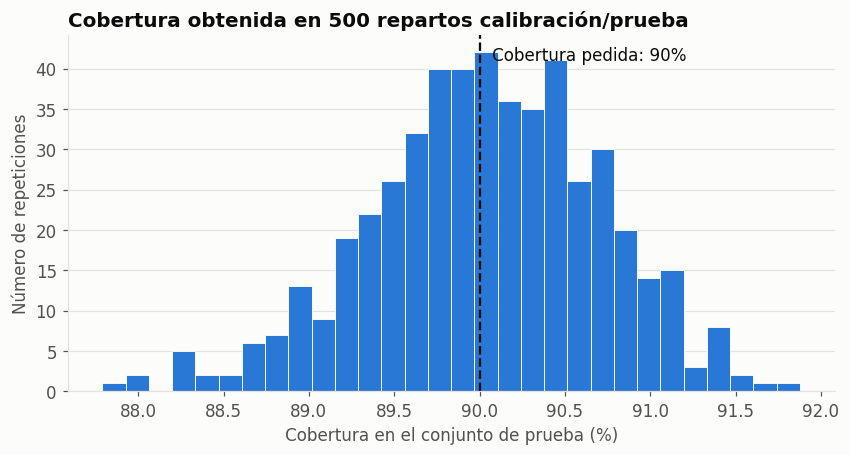

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.hist(coberturas * 100, bins=30, color=AZUL, edgecolor=FONDO, linewidth=0.6)
ax.axvline((1 - ALPHA) * 100, color=TEXTO, linewidth=1.5, linestyle="--")
ax.annotate(f"Cobertura pedida: {1 - ALPHA:.0%}", xy=((1 - ALPHA) * 100, ax.get_ylim()[1] * 0.97),
            xytext=(8, 0), textcoords="offset points", va="top", color=TEXTO)
ax.set_title("Cobertura obtenida en 500 repartos calibración/prueba")
ax.set_xlabel("Cobertura en el conjunto de prueba (%)")
ax.set_ylabel("Número de repeticiones")
fig.savefig(FIG_DIR / "03_cobertura_repeticiones.png")
plt.show()

La cobertura se concentra alrededor del 90%: unas particiones dan un poco más y otras un poco menos, pero el promedio coincide con lo pedido. Esa es la garantía **marginal**.

## 8. Una limitación: el ancho es igual para todos

Con el puntaje $|y - \hat{y}|$ el intervalo es $\hat{y} \pm \hat{q}$ para cualquier vivienda. Pero el modelo no se equivoca igual en todas partes. Si separamos los distritos de prueba en cuatro grupos según el valor predicho, la cobertura **no** es 90% en cada grupo.

In [13]:
grupos = ["25% más barato", "Medio-bajo", "Medio-alto", "25% más caro"]
resultado["grupo"] = pd.qcut(resultado["prediccion"], 4, labels=grupos)

por_grupo = (resultado.assign(error=(resultado["valor_real"] - resultado["prediccion"]).abs())
             .groupby("grupo", observed=True)
             .agg(error_medio=("error", "mean"), cobertura=("cubierto", "mean")))
por_grupo["ancho_intervalo"] = 2 * q_hat
por_grupo["cobertura"] = por_grupo["cobertura"].map("{:.1%}".format)
por_grupo.round(1)

,error_medio,cobertura,ancho_intervalo
grupo,,,
25% más barato,17.2,98.4%,150.2
Medio-bajo,24.6,95.7%,150.2
Medio-alto,37.9,87.8%,150.2
25% más caro,47.5,78.6%,150.2


Los distritos baratos reciben un intervalo más ancho de lo necesario (en la gráfica anterior algunos límites inferiores llegan a ser negativos) y los caros uno demasiado angosto. El 90% se cumple **en promedio**, no dentro de cada grupo.

## 9. Extra: intervalos adaptativos con CQR

**Conformalized Quantile Regression** cambia dos cosas:

- En lugar de un modelo que predice la media, se entrenan dos modelos que predicen los cuantiles 5% y 95%. Eso ya da un intervalo de ancho variable, pero sin garantía.
- El puntaje pasa a ser cuánto se sale el valor real de ese intervalo: $s_i = \max(\hat{q}_{inf}(x_i) - y_i,\ y_i - \hat{q}_{sup}(x_i))$

El resto es idéntico: mismo conjunto de calibración, misma función `cuantil_conformal`.

Como modelos de cuantiles usamos gradient boosting (`HistGradientBoostingRegressor` con `loss="quantile"`). En la gráfica, la predicción del Random Forest aparece solo como referencia: el intervalo de CQR sale de los dos modelos de cuantiles, no de ella.

In [14]:
m_inf = HistGradientBoostingRegressor(loss="quantile", quantile=ALPHA / 2, random_state=SEED).fit(X_train, y_train)
m_sup = HistGradientBoostingRegressor(loss="quantile", quantile=1 - ALPHA / 2, random_state=SEED).fit(X_train, y_train)

# Intervalo de los modelos de cuantiles, sin calibrar
cobertura_sin_calibrar = np.mean((y_test >= m_inf.predict(X_test)) & (y_test <= m_sup.predict(X_test)))

# Calibración conformal
puntajes_cqr = np.maximum(m_inf.predict(X_cal) - y_cal, y_cal - m_sup.predict(X_cal)).to_numpy()
q_cqr = cuantil_conformal(puntajes_cqr, ALPHA)

res_cqr = pd.DataFrame({
    "valor_real": y_test.to_numpy(),
    "prediccion": pred_test,
    "inferior": m_inf.predict(X_test) - q_cqr,
    "superior": m_sup.predict(X_test) + q_cqr,
})
res_cqr["cubierto"] = res_cqr["valor_real"].between(res_cqr["inferior"], res_cqr["superior"])
res_cqr["ancho"] = res_cqr["superior"] - res_cqr["inferior"]
res_cqr["grupo"] = resultado["grupo"].to_numpy()

print(f"Cobertura de los cuantiles sin calibrar: {cobertura_sin_calibrar:.1%}")
print(f"Corrección conformal q̂:                 {q_cqr:+.1f} mil USD a cada lado")
print(f"Cobertura de CQR:                        {res_cqr['cubierto'].mean():.1%}")
print(f"Ancho del intervalo: de {res_cqr['ancho'].min():.0f} a {res_cqr['ancho'].max():.0f} mil USD "
      f"(promedio {res_cqr['ancho'].mean():.0f})")

c:\Users\ASUS\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\ASUS\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\ASUS\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\ASUS\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1024, in __init__
    self._execute_child(args, executable, preexec_fn, close

Cobertura de los cuantiles sin calibrar: 84.4%
Corrección conformal q̂:                 +5.5 mil USD a cada lado
Cobertura de CQR:                        90.5%
Ancho del intervalo: de 32 a 431 mil USD (promedio 157)


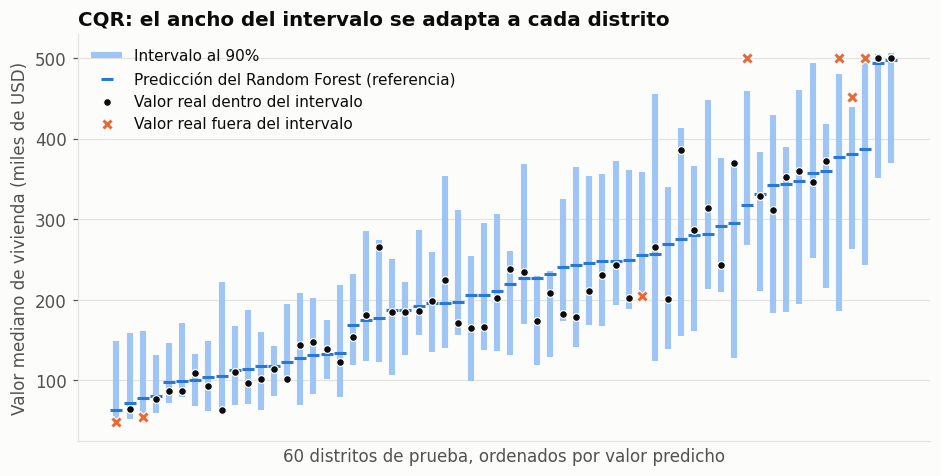

En esta muestra: 53 de 60 valores reales dentro del intervalo


In [15]:
grafica_intervalos(res_cqr, "CQR: el ancho del intervalo se adapta a cada distrito",
                   "04_intervalos_cqr.png", etiqueta_pred="Predicción del Random Forest (referencia)")

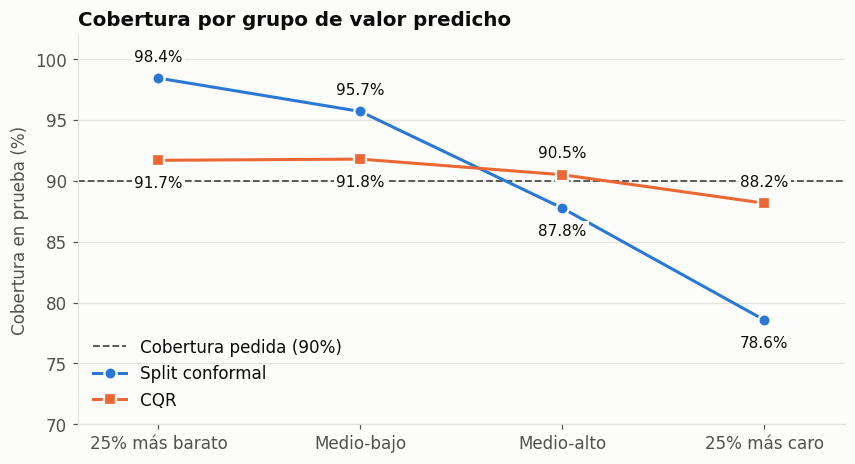

,Split conformal,CQR
grupo,,
25% más barato,98.4,91.7
Medio-bajo,95.7,91.8
Medio-alto,87.8,90.5
25% más caro,78.6,88.2


In [16]:
comparacion = pd.DataFrame({
    "Split conformal": resultado.groupby("grupo", observed=True)["cubierto"].mean() * 100,
    "CQR": res_cqr.groupby("grupo", observed=True)["cubierto"].mean() * 100,
}).reindex(grupos)

fig, ax = plt.subplots(figsize=(9, 4.6))
x = np.arange(len(comparacion))
ax.axhline((1 - ALPHA) * 100, color=TEXTO_2, linewidth=1.2, linestyle="--",
           label=f"Cobertura pedida ({1 - ALPHA:.0%})")
estilos = {"Split conformal": (AZUL, "o"), "CQR": (NARANJA, "s")}
for nombre, (color, marcador) in estilos.items():
    otro = comparacion.drop(columns=nombre).iloc[:, 0]
    ax.plot(x, comparacion[nombre], color=color, marker=marcador, markersize=8, linewidth=2,
            markeredgecolor=FONDO, markeredgewidth=1.5, label=nombre, zorder=3)
    for xi, v, v_otro in zip(x, comparacion[nombre], otro):
        dy = 14 if v >= v_otro else -15      # la serie más alta se rotula arriba, la otra abajo
        ax.annotate(f"{v:.1f}%", (xi, v), xytext=(0, dy), textcoords="offset points",
                    ha="center", va="center", fontsize=10, color=TEXTO, zorder=4,
                    bbox=dict(facecolor=FONDO, edgecolor="none", pad=1.5))
ax.set_xticks(x, comparacion.index)
ax.set_xlim(-0.4, len(x) - 0.6)
ax.set_ylim(70, 102)
ax.set_title("Cobertura por grupo de valor predicho")
ax.set_ylabel("Cobertura en prueba (%)")
ax.legend(loc="lower left")
fig.savefig(FIG_DIR / "05_cobertura_por_grupo.png")
plt.show()

comparacion.round(1)

## 10. Resumen

In [17]:
resumen = pd.DataFrame([
    {"método": "Ingenuo (errores de entrenamiento)", "cobertura": cobertura_ingenua,
     "ancho promedio": 2 * margen_ingenuo, "ancho variable": "no"},
    {"método": "Split conformal", "cobertura": resultado["cubierto"].mean(),
     "ancho promedio": 2 * q_hat, "ancho variable": "no"},
    {"método": "CQR", "cobertura": res_cqr["cubierto"].mean(),
     "ancho promedio": res_cqr["ancho"].mean(), "ancho variable": "sí"},
])
resumen["cobertura"] = resumen["cobertura"].map("{:.1%}".format)
resumen["ancho promedio"] = resumen["ancho promedio"].round(1)
print(f"Cobertura pedida: {1 - ALPHA:.0%}")
resumen.set_index("método")

Cobertura pedida: 90%


,cobertura,ancho promedio,ancho variable
método,,,
Ingenuo (errores de entrenamiento),62.3%,56.0,no
Split conformal,90.1%,150.2,no
CQR,90.5%,157.1,sí


**Qué muestra el experimento**

- Sin calibración, un intervalo que promete 90% no lo cumple.
- Split conformal alcanza la cobertura pedida con muy poco código y sin tocar el modelo.
- La garantía es **marginal**: se cumple en promedio, no dentro de cada subgrupo.
- La validez viene del método; qué tan útiles son los intervalos depende del modelo y del puntaje elegido. CQR usa la misma calibración y reparte mejor el ancho.

**Supuesto.** Todo depende de que los datos de calibración y los datos nuevos sean intercambiables. Aquí se cumple porque la partición es aleatoria; con datos de otra región u otra época, la garantía ya no aplica.